# Fuga por capitalización diaria: el valor de referencia de LiST de 12,11% a los 125 días

**Pregunta:** ¿Cuánto de los depósitos de un banco saca una tasa diaria constante de fuga en 125 días, y qué tan lejos está la tasa suave de la prueba de tensión del BCE de la velocidad de las corridas de 2023?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (la escalera, la NLP y el período de supervivencia)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar la salida acumulada de una tasa diaria constante de fuga, $1-(1-q)^n$, y reproducir el valor de referencia de la prueba de tensión de liquidez del BCE (12,11% a los 125 días) con cada intermedio;
- invertirla, para convertir una corrida observada ("85% en 2 días") en la tasa diaria que la produce, y ver cuán lejos están entre sí las corridas de la Tabla A.1;
- construir día a día las salidas de un segmento, con el vencimiento contractual y la regla de no renovación de los depósitos financieros;
- contrastar una salida modelada con una corrida observada y leer la luz del semáforo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
# Etiquetas en español de los semáforos de las pruebas de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos documentos versionados del caso C16 (el balance del banco que quebró el 2023-03-10: agregados reales del reporte de llamada de la FDIC, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `data/derived/C16/list-adverse.json`: las salidas diarias de cada segmento de depósitos bajo la fuga del escenario Adverso de LiST 2019 del BCE, y la evaluación frente a la corrida de marzo de 2023.
- `data/derived/C16/lcr-standard.json`: las filas de prueba versionadas de las pruebas de fuga (el valor de referencia de LiST y la contrastación frente a las salidas del LCR a 30 días).

Las tasas de fuga son las Tablas 3.2 y 3.3 transcritas de la nota metodológica del BCE, que el motor guarda como datos del módulo (`LIST_PARAMETERS`); las corridas observadas son la Tabla A.1 del informe del BCBS sobre la turbulencia de 2023 (`TABLE_A1`).

In [2]:
# Cargar los dos documentos versionados (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
adverse = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
standard = json.loads((ROOT / "data" / "derived" / "C16" / "lcr-standard.json").read_text(encoding="utf-8"))
out = adverse["outputs"]

for name, doc in (("list-adverse", adverse), ("lcr-standard", standard)):
    baked = doc["provenance"]["riskvalidation_version"]
    print(name, "| calculado con riskvalidation", baked, "| instalado", rv.__version__)

list-adverse | calculado con riskvalidation 1.0.1 | instalado 1.0.1
lcr-standard | calculado con riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: la salida acumulada de una tasa diaria constante

Los depósitos de vencimiento abierto de LiST (depósitos a la vista sin término contractual) se fugan a una tasa diaria constante $q$ capitalizada sobre el stock del día anterior, contada en días relevantes (BCE, 2019, nota metodológica, Tabla 3.3, párrafo 107). Tras $n$ días la proporción de salida acumulada es:

$$F(n) = 1 - (1 - q)^n$$

El valor de referencia es el ejemplo de la propia nota: los depósitos minoristas estables bajo el choque Adverso tienen $q = 0{,}103258\%$ por día relevante, y los seis meses tienen $n = 125$ días relevantes, lo que da $F(125) \approx 12{,}11\%$. La celda siguiente muestra los tres intermedios (la base $1-q$, su potencia y el complemento) y luego llama a `cumulative_outflow_constant`.

In [3]:
# El ejemplo de referencia de la nota de LiST: cada intermedio, y luego el motor
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, cumulative_outflow_constant

q = LIST_PARAMETERS["adverse"]["open_maturity"]["stable-retail"]
n = 125
base = 1.0 - q
power = base**n

print("q =", q, "| n =", n)
print("1 - q =", round(base, 8))
print("(1 - q)^n =", round(power, 8))
print("1 - (1 - q)^n =", round(1.0 - power, 8))
print("motor, cumulative_outflow_constant(q, n):", round(cumulative_outflow_constant(q, n), 8))

q = 0.00103258 | n = 125
1 - q = 0.99896742
(1 - q)^n = 0.87885163
1 - (1 - q)^n = 0.12114837
motor, cumulative_outflow_constant(q, n): 0.12114837


Esto es una verificación de la ecuación sobre un número, no una segunda implementación: la función del motor además valida sus entradas (una tasa en $[0,1]$, un número entero no negativo de días) y acepta arreglos. El producto envuelve el valor de referencia como una prueba de validación, `liq.list_compounding_golden`, cuyo estadístico es la distancia al valor impreso de la nota. La celda siguiente la llama.

In [4]:
# El valor de referencia como TestResult: la prueba de validación del producto sobre el ejemplo de capitalización
from riskvalidation.validation.liquidity import list_compounding_golden

golden = list_compounding_golden()

print("test_id:", golden.test_id)
print("salida acumulada:", round(golden.metric, 8), "| observaciones n:", golden.n)
print("distancia al 12,11 por ciento impreso:", golden.statistic)
print("semáforo:", LIGHTS[golden.light.value])

test_id: liq.list_compounding_golden
salida acumulada: 0.12114837 | observaciones n: 125
distancia al 12,11 por ciento impreso: 3.6571242759131373e-07
semáforo: verde


### Paso 2: la inversa, de una corrida observada a una tasa diaria

Una corrida observada se informa como una proporción $F$ de los depósitos perdida en $n$ días. La tasa diaria constante que se compone hasta ella es la inversa de la ecuación anterior:

$$q = 1 - (1 - F)^{1/n}$$

La Tabla A.1 del informe del BCBS sobre la turbulencia de 2023 (BCBS, 2023) lista nueve corridas, desde Northern Rock en 2007 hasta Silicon Valley Bank en 2023. El motor las guarda como `TABLE_A1` y calcula cada tasa implícita con `daily_rate_from_cumulative`. La revisión de la Reserva Federal sobre el banco (Federal Reserve, 2023) es la fuente del 85% en dos días. La celda siguiente lista las filas de la más lenta a la más rápida.

In [5]:
# La tasa diaria implícita de cada corrida de la Tabla A.1, de la más lenta a la más rápida
from riskvalidation.liquidity.runoff import TABLE_A1, daily_rate_from_cumulative

table = sorted(TABLE_A1, key=lambda r: r.implied_daily_rate)
implied = [daily_rate_from_cumulative(run.outflow_share, run.days) for run in table]

print(f"{'banco':16s}{'año':>6s}{'salida':>10s}{'días':>6s}{'tasa diaria':>14s}")
for run, rate in zip(table, implied):
    print(f"{run.bank:16s}{run.year:6d}{run.outflow_share:10.2f}{run.days:6d}{rate:14.6f}")
print("la más rápida sobre la más lenta:", round(implied[-1] / implied[0], 1))

banco              año    salida  días   tasa diaria
Credit Suisse     2023      0.21    90      0.002616
Icesave           2008      0.20    75      0.002971
IndyMac           2008      0.08    14      0.005938
First Republic    2023      0.57    90      0.009334
WaMu              2008      0.10    10      0.010481
Northern Rock     2007      0.20     4      0.054258
Signature         2023      0.20     1      0.200000
SVB UK            2023      0.30     1      0.300000
SVB               2023      0.85     2      0.612702
la más rápida sobre la más lenta: 234.2


La celda siguiente dibuja la tasa diaria implícita de cada corrida en un eje logarítmico, las corridas de 2023 en rojo, con la tasa minorista estable de LiST como línea segmentada.

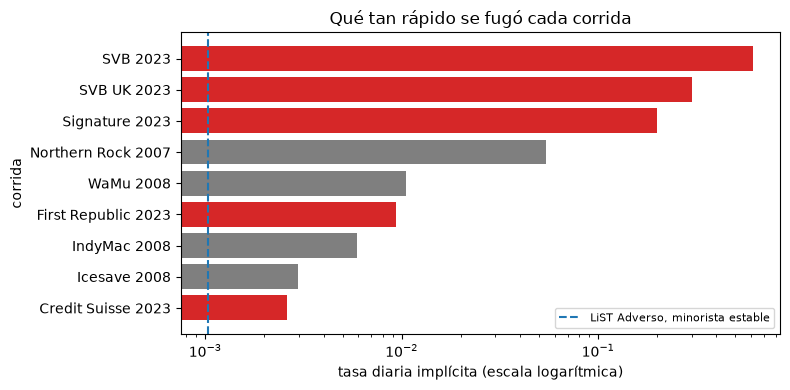

In [6]:
# Dibujar la tasa diaria implícita de cada corrida en un eje logarítmico, las corridas de 2023 en rojo
names = [f"{run.bank} {run.year}" for run in table]
colors = ["tab:red" if run.year == 2023 else "tab:gray" for run in table]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(names, implied, color=colors)
ax.axvline(q, color="tab:blue", linestyle="--", label="LiST Adverso, minorista estable")
ax.set_xscale("log")
ax.set_xlabel("tasa diaria implícita (escala logarítmica)")
ax.set_ylabel("corrida")
ax.set_title("Qué tan rápido se fugó cada corrida")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las barras ponen corridas muy distintas en una misma escala. La línea segmentada es la tasa minorista estable de LiST, 0,00103258 al día, y queda a la izquierda de toda barra: incluso la corrida más lenta de la tabla, Credit Suisse con 0,002616 al día, se fuga más rápido de lo que la prueba de tensión supone para su clase más estable. Las cinco corridas de 2023 en rojo se reparten en dos órdenes de magnitud, de 0,009334 para First Republic a 0,612702 para SVB, y la más rápida es 234,2 veces la más lenta. La figura compara tasas, no exposiciones: cada corrida tuvo su propia proporción de depósitos asegurados, que la tabla no da.

### Paso 3: las salidas de un segmento, día a día

Cuando la tasa cambia con el estado de la tensión, la salida acumulada es el producto de las supervivencias diarias, y la salida del día $d$ es el stock aún depositado por la tasa de ese día:

$$F(n) = 1 - \prod_{d \le n} (1 - q_d), \qquad O_s(d) = B_s \prod_{k < d} (1 - q_k)\; q_d$$

$B_s$ es el saldo inicial del segmento $s$. El motor tiene `cumulative_outflow_path` para la primera y `behavioural_outflows` para la segunda (multiplica la proporción de stock del día anterior por la tasa, de modo que nunca resta dos números casi iguales). La celda siguiente reconstruye el segmento minorista asegurado del documento a partir de su saldo inicial y sus 125 tasas diarias, e imprime los tres primeros días como intermedios.

In [7]:
# Reconstruir el segmento minorista asegurado desde su saldo inicial y sus tasas diarias
from riskvalidation.liquidity.ladder import behavioural_outflows
from riskvalidation.liquidity.runoff import cumulative_outflow_path

segments = {s["segment"]: s for s in out["path"]["ladder"]["segments"]}
retail = segments["retail-insured"]
opening = np.array([retail["opening_balance"]])
rates = np.array([retail["daily_rates"]])
flows = behavioural_outflows(opening, rates)[0]
cumulative = cumulative_outflow_path(rates[0])

print("saldo inicial (miles de USD):", opening[0], "| días:", rates.shape[1])
print("tasa diaria del día 1:", rates[0, 0])
survival = 1.0
for day in range(3):
    outflow = opening[0] * survival * rates[0, day]
    print(f"día {day + 1} | aún depositado {survival:.8f} | tasa {rates[0, day]}")
    print(f"      salida {outflow:.4f} | motor {flows[day]:.4f}")
    survival *= 1.0 - rates[0, day]
print("proporción acumulada al día 125:", round(cumulative[-1], 6))

saldo inicial (miles de USD): 9990000.0 | días: 125
tasa diaria del día 1: 0.00373218
día 1 | aún depositado 1.00000000 | tasa 0.00373218
      salida 37284.4782 | motor 37284.4782
día 2 | aún depositado 0.99626782 | tasa 0.00373218
      salida 37145.3258 | motor 37145.3258
día 3 | aún depositado 0.99254957 | tasa 0.00373218
      salida 37006.6928 | motor 37006.6928
proporción acumulada al día 125: 0.373368


Las mismas dos funciones aceptan una tasa que cambia. Como exploración, no como escenario versionado, la celda siguiente duplica la tasa de este segmento del día 11 al día 20 y compara la salida acumulada al día 125 con el caso constante: importa la trayectoria, no solo la tasa media.

In [8]:
# Una tasa que se duplica en los días 11 a 20 (una exploración, no un escenario versionado)
what_if = rates[0].copy()
what_if[10:20] *= 2.0
path_what_if = cumulative_outflow_path(what_if)
extra = opening[0] * (path_what_if[-1] - cumulative[-1])

print("salida acumulada al día 125, tasa constante:", round(cumulative[-1], 6))
print("salida acumulada al día 125, duplicada en los días 11 a 20:", round(path_what_if[-1], 6))
print("salida adicional (miles de USD):", round(extra, 2))

salida acumulada al día 125, tasa constante: 0.373368
salida acumulada al día 125, duplicada en los días 11 a 20: 0.39645
salida adicional (miles de USD): 230597.75


La celda siguiente dibuja ambas trayectorias: la salida de cada día a la izquierda y la proporción acumulada del segmento a la derecha.

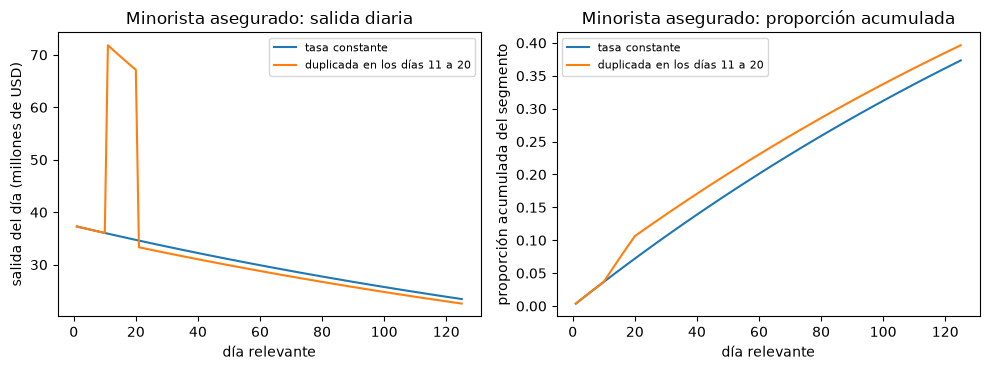

In [9]:
# Dibujar la salida diaria y la proporción acumulada del segmento, tasa constante y duplicada en los días 11 a 20
days = np.arange(1, rates.shape[1] + 1)
flows_what_if = behavioural_outflows(opening, what_if[None, :])[0]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.plot(days, flows / 1e3, label="tasa constante")
left.plot(days, flows_what_if / 1e3, label="duplicada en los días 11 a 20")
left.set_xlabel("día relevante")
left.set_ylabel("salida del día (millones de USD)")
left.set_title("Minorista asegurado: salida diaria")
left.legend(fontsize=8)
right.plot(days, cumulative, label="tasa constante")
right.plot(days, path_what_if, label="duplicada en los días 11 a 20")
right.set_xlabel("día relevante")
right.set_ylabel("proporción acumulada del segmento")
right.set_title("Minorista asegurado: proporción acumulada")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

El panel izquierdo muestra la salida diaria achicándose despacio bajo la tasa constante (37.284,48 miles de USD el día 1 y 37.145,33 el día 2, porque el stock se achica mientras la tasa no), saltando mientras la tasa se duplica en los días 11 a 20, y volviendo luego apenas bajo la trayectoria base, porque queda menos stock que fugar. El panel derecho muestra la consecuencia: la proporción acumulada termina en 0,39645 en vez de 0,373368, es decir, 230.597,75 miles de USD más. Una duplicación temporal deja una marca permanente, así que importa la trayectoria de la tasa y no solo su promedio. La figura es una exploración, no un escenario versionado.

### Paso 4: el vencimiento contractual y los depósitos financieros

No todo pasivo es de vencimiento abierto. Un pasivo contractual sale del balance cuando vence, y LiST aplica a cada flujo que vence una tasa de salida constante por clase (Tabla 3.2, párrafo 94); el resto se supone renovado y queda más allá del horizonte. Los depósitos interbancarios y otros financieros que vencen no se renuevan en absoluto (párrafo 98, tasa 1). El motor tiene `contractual_rolloff` y `financial_no_rollover`; los depósitos a la vista de clientes financieros salen completos el primer día relevante (párrafo 111), que es como el documento corre su segmento `financial`. La celda siguiente muestra las tres reglas.

In [10]:
# Vencimiento contractual de un flujo, la regla de no renovación y el segmento financiero del documento
from riskvalidation.liquidity.runoff import contractual_rolloff, financial_no_rollover

maturing = np.array([100.0, 50.0])
stable_rate = LIST_PARAMETERS["adverse"]["contractual_outflow"]["stable-retail"]
print("tasa de salida contractual del minorista estable, Adverso:", stable_rate)
print("un flujo de [100, 50] que vence, minorista estable:", contractual_rolloff(maturing, stable_rate))
print("el mismo flujo, un depósito financiero:", financial_no_rollover(maturing))

financial = segments["financial"]
horizon = len(financial["outflows"])
full = behavioural_outflows(np.array([financial["opening_balance"]]), np.ones((1, horizon)))[0]
print("segmento financiero, tasa 1 todos los días, tres primeros días:", full[:3])

tasa de salida contractual del minorista estable, Adverso: 0.18
un flujo de [100, 50] que vence, minorista estable: [18.  9.]
el mismo flujo, un depósito financiero: [100.  50.]
segmento financiero, tasa 1 todos los días, tres primeros días: [13899000.        0.        0.]


### Paso 5: la contrastación con una corrida observada

Un supuesto de fuga puede contrastarse con lo ocurrido. La prueba `liq.runoff_adequacy_back_test` compara la proporción de salida modelada con la realizada (los supuestos de Basilea frente a la tasa observada):

$$\text{ratio} = \frac{\text{modelled share}}{\text{realised share}}, \qquad \text{shortfall} = \text{realised share} - \text{modelled share}$$

Es un puntaje descriptivo sobre un evento real, sin valor p. El semáforo es una compuerta interna de Contraste (verde desde una razón de 0,8, ámbar desde 0,5, rojo por debajo), no un umbral regulatorio. La proporción realizada es el "cerca de 85 por ciento" de la base de depósitos en dos días de la Reserva Federal (Federal Reserve, 2023); la proporción modelada es la suma de los dos primeros días de las salidas por segmento del documento sobre la base de depósitos del modelo. La celda siguiente calcula la proporción modelada y llama a la prueba.

In [11]:
# Contrastar las salidas de los dos primeros días de LiST Adverso frente al 85 por ciento observado en dos días
from riskvalidation.validation.liquidity import runoff_adequacy_back_test

evaluation = out["scoring"]
base_deposits = evaluation["model_deposit_base"]
first_two_days = sum(sum(s["outflows"][:2]) for s in out["path"]["ladder"]["segments"])
modelled = first_two_days / base_deposits
board = evaluation["denominators"][0]
test = runoff_adequacy_back_test(
    modelled, board["realised_share"], compared_at="event-horizon", denominator=board["id"]
)

print("salida de los dos primeros días (miles de USD):", round(first_two_days, 2))
print("base de depósitos del modelo (miles de USD):", base_deposits)
print("proporción modelada:", round(modelled, 6), "| proporción realizada:", board["realised_share"])
print("razón:", round(test.statistic, 6), "| déficit:", round(test.metric, 6), "| semáforo:", LIGHTS[test.light.value])
# la misma prueba en el horizonte de modelo de 30 días de la variante LCR, tal como la calculó el producto
for row in standard["tests"]:
    if row["test_id"] == "liq.runoff_adequacy_back_test":
        ratio = round(row["statistic"], 6)
        print("modelo a 30 días |", row["segment"], "| razón:", ratio, "| semáforo:", LIGHTS[row["light"]])

salida de los dos primeros días (miles de USD): 16053789.14
base de depósitos del modelo (miles de USD): 175481000.0
proporción modelada: 0.091484 | proporción realizada: 0.85
razón: 0.107629 | déficit: 0.758516 | semáforo: rojo
modelo a 30 días | board-stated-share | razón: 0.506405 | semáforo: ámbar
modelo a 30 días | call-report-dep | razón: 0.539534 | semáforo: ámbar


La celda siguiente dibuja la lección central del notebook: las salidas acumuladas suaves de LiST Adverso de tres clases en 125 días, y las nueve corridas de la Tabla A.1 como puntos en su propio horizonte.

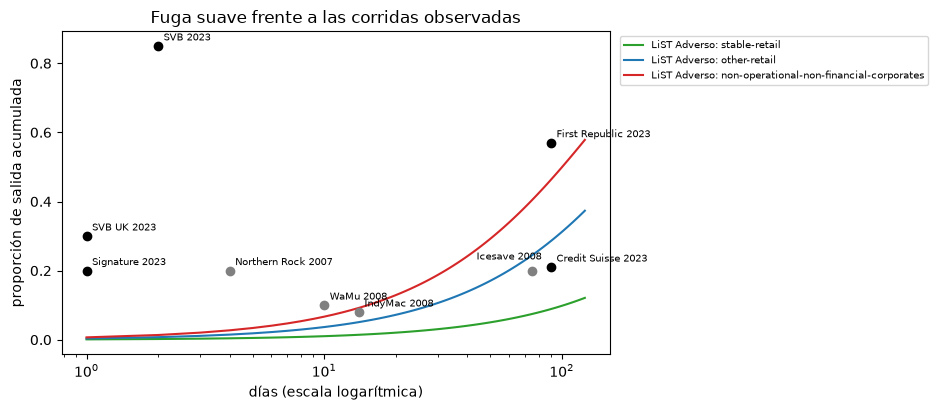

In [12]:
# Dibujar las curvas suaves de LiST Adverso frente a las corridas de la Tabla A.1
fig, ax = plt.subplots(figsize=(9.5, 4.2))
days = np.arange(1, 126)
open_maturity = LIST_PARAMETERS["adverse"]["open_maturity"]
classes = (
    ("stable-retail", "tab:green"),
    ("other-retail", "tab:blue"),
    ("non-operational-non-financial-corporates", "tab:red"),
)
for name, color in classes:
    curve = cumulative_outflow_constant(open_maturity[name], days)
    ax.plot(days, curve, color=color, label=f"LiST Adverso: {name}")
for run in TABLE_A1:
    ax.scatter(run.days, run.outflow_share, color="black" if run.year == 2023 else "gray", zorder=3)
    offset = (-40, 8) if run.row_id == "icesave-2008" else (4, 4)
    label = f"{run.bank} {run.year}"
    ax.annotate(label, (run.days, run.outflow_share), textcoords="offset points", xytext=offset, fontsize=7)
ax.set_xscale("log")
ax.set_xlabel("días (escala logarítmica)")
ax.set_ylabel("proporción de salida acumulada")
ax.set_title("Fuga suave frente a las corridas observadas")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

Toda curva suave queda bajo cuatro de las cinco corridas de 2023 (SVB, SVB UK, Signature y First Republic); solo la corrida de Credit Suisse, de 90 días, queda bajo las dos curvas más rápidas. Las corridas lentas de 2008 quedan cubiertas con holgura. Las tasas de la prueba de tensión describen una fuga lenta, y las corridas rápidas de 2023 describen otra cosa. El eje logarítmico comprime el tiempo, así que las corridas de uno y dos días quedan en el borde izquierdo, donde las curvas apenas han empezado: ahí es donde la distancia entre el supuesto y el evento es mayor.

## Resultados

**Respuesta:** Una tasa diaria constante de 0,00103258 (minorista estable bajo LiST Adverso) saca 0,12114837 de los depósitos en 125 días, el 12,11% del propio ejemplo del BCE. Ese supuesto suave está lejos de las corridas de 2023: la tasa diaria implícita de SVB, 85% en 2 días, es 0,612702, 234,2 veces la corrida más lenta de la Tabla A.1, y la salida de LiST Adverso de los dos primeros días es 0,091484 de la base de depósitos frente al 0,85 observado, una razón de 0,107629.

- **El valor de referencia.** La base, su potencia 125 y el complemento son 0,99896742, 0,87885163 y 0,12114837, y el motor devuelve el mismo valor. La prueba de referencia del producto informa una distancia de cerca de 3,7e-07 al 12,11% impreso.
- **La inversa.** La tasa diaria implícita de las corridas va de 0,002616 (Credit Suisse, 21% en 90 días) a 0,612702 (SVB, 85% en 2 días): la más rápida es 234,2 veces la más lenta. La tasa minorista estable de la nota, 0,00103258, es menor que la de la corrida más lenta de la tabla.
- **El segmento.** El segmento minorista asegurado pierde 37.284,48 miles de USD el día 1 y 37.145,33 el día 2 (el stock se achica, la tasa no) y 0,373368 de su stock a los 125 días. Duplicar la tasa en los días 11 a 20 sube la salida acumulada de 0,373368 a 0,39645, es decir, 230.597,75 miles de USD más. Un flujo contractual de [100, 50] de minorista estable vence como [18, 9], el mismo flujo de un depósito financiero sale completo, y el segmento financiero del documento sale con 13.899.000 miles de USD el día 1.
- **La contrastación.** La salida de LiST Adverso de los dos primeros días es 16.053.789,14 miles de USD, 0,091484 de la base de depósitos del modelo. Frente al 0,85 de la Reserva Federal esto es una razón de 0,107629 y un déficit de 0,758516, rojo bajo las compuertas internas. Frente a las salidas del LCR a 30 días (el horizonte del modelo) las dos filas calculadas son ámbar, con razones de 0,506405 y 0,539534. El supuesto suave está lejos del evento que debe cubrir; las filas describen un evento real con depósitos sintéticos, una observación y ningún valor p, así que muestran el tamaño de la brecha, no una probabilidad.

Lo que este notebook no muestra: cómo se construye el CBC frente al que se ponen estas salidas (notebook 03), cómo se componen los segmentos en un escenario (notebook 04) o qué dice el LCR (notebook 05).

## Resumen

- Una tasa diaria constante $q$ se compone hasta $1-(1-q)^n$ tras $n$ días; el valor de referencia de LiST (12,11% a los 125 días con 0,103258% diario) se reproduce con la precisión impresa.
- Su inversa convierte cualquier corrida observada en una tasa diaria, lo que pone corridas muy distintas en una misma escala.
- Las salidas de un segmento son el stock aún depositado por la tasa diaria; los pasivos contractuales vencen por clase y los depósitos financieros no se renuevan.
- Una contrastación pone la salida modelada frente a una corrida observada; bajo las compuertas internas del producto la salida de LiST Adverso de los dos primeros días es roja frente al 85% de marzo de 2023.

**Qué probar a continuación.** Cambia el día y la tasa de la exploración (una duplicación en los días 1 a 5) y mira cuánto de la salida acumulada viene de la primera semana; luego sigue con el notebook 03.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Tables 3.2 and 3.3 and paragraphs 94, 98, 107 and 111. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf